In [1]:
import pandas as pd
import matplotlib.pylab as plt
import numpy as np
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_fscore_support
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
import joblib




In [2]:
df_clean = pd.read_csv('../data/processed/card_profiler_clean.csv')

In [3]:
df_clean.columns

Index(['CUST_ID', 'BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES',
       'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS',
       'cluster_kmeans', 'cluster_dbscan', 'est_atypique_dbscan',
       'cluster_final', 'target'],
      dtype='str')

target
Low-Activity Customers    0.379
At-Risk Customers         0.350
Premium Customers         0.271
Name: proportion, dtype: float64


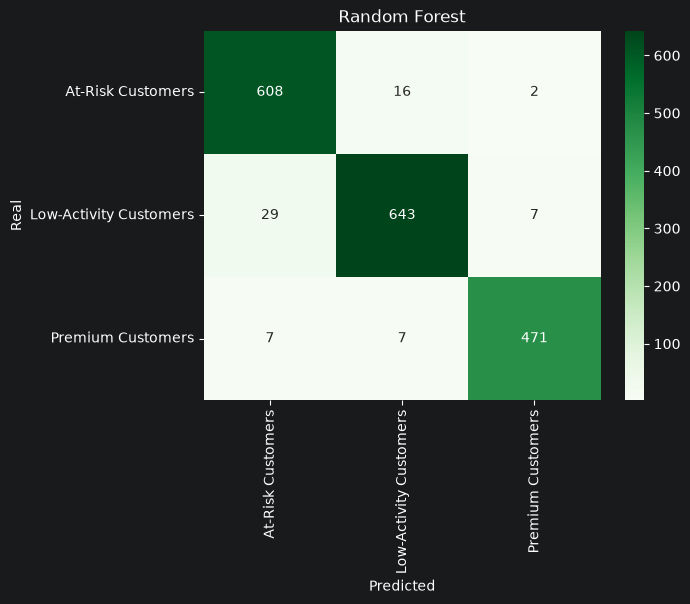

In [4]:

drop_cols = ["target", "cluster_kmeans", "cluster_dbscan", "est_atypique_dbscan", "cluster_final"]
X = df_clean.drop(columns=[c for c in drop_cols if c in df_clean.columns])
X = X.select_dtypes("number")
y = df_clean["target"]

print(y.value_counts(normalize=True).round(3))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

rows = []
cv_scores = {}

pipe_rf = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(class_weight="balanced", random_state=42)),
])

pipe_rf.fit(X_train, y_train)

pred = pipe_rf.predict(X_test)
prec, rec, f1, _ = precision_recall_fscore_support(y_test, pred, average="weighted")
rows.append({
    "model": "Random Forest",
    "accuracy": accuracy_score(y_test, pred),
    "precision": prec,
    "recall": rec,
    "f1": f1,
})

cv_scores["Random Forest"] = cross_val_score(pipe_rf, X_train, y_train, cv=5, scoring="f1_weighted")

labels = pipe_rf.classes_
sns.heatmap(confusion_matrix(y_test, pred, labels=labels), annot=True, fmt="d", xticklabels=labels,  cmap="Greens" ,yticklabels=labels)
plt.title("Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Real")
plt.show()


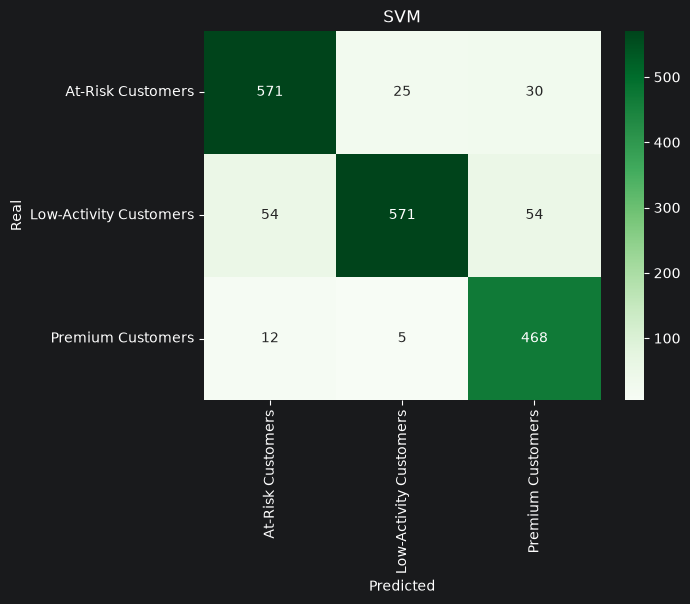

In [5]:


pipe_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(class_weight="balanced")),
])

pipe_svm.fit(X_train, y_train)

pred = pipe_svm.predict(X_test)
prec, rec, f1, _ = precision_recall_fscore_support(y_test, pred, average="weighted")
rows.append({"model": "SVM", "accuracy": accuracy_score(y_test, pred),
             "precision": prec, "recall": rec, "f1": f1})
cv_scores["SVM"] = cross_val_score(pipe_svm, X_train, y_train, cv=5, scoring="f1_weighted")

sns.heatmap(confusion_matrix(y_test, pred, labels=labels), annot=True, fmt="d",
            cmap="Greens", xticklabels=labels, yticklabels=labels)
plt.title("SVM")
plt.xlabel("Predicted")
plt.ylabel("Real")
plt.show()


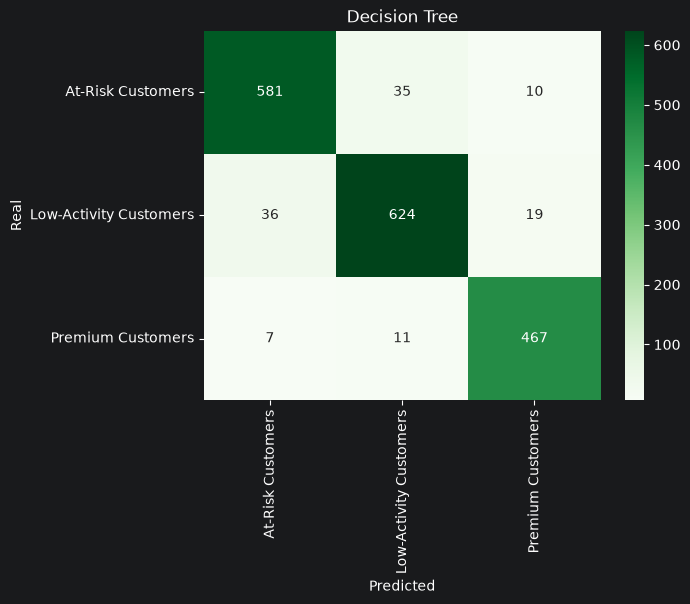

In [6]:


pipe_dt = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", DecisionTreeClassifier(class_weight="balanced", random_state=42)),
])

pipe_dt.fit(X_train, y_train)

pred = pipe_dt.predict(X_test)
prec, rec, f1, _ = precision_recall_fscore_support(y_test, pred, average="weighted")
rows.append({"model": "Decision Tree", "accuracy": accuracy_score(y_test, pred),
             "precision": prec, "recall": rec, "f1": f1})
cv_scores["Decision Tree"] = cross_val_score(pipe_dt, X_train, y_train, cv=5, scoring="f1_weighted")

sns.heatmap(confusion_matrix(y_test, pred, labels=labels), annot=True, fmt="d",
            cmap="Greens", xticklabels=labels, yticklabels=labels)
plt.title("Decision Tree")
plt.xlabel("Predicted")
plt.ylabel("Real")
plt.show()

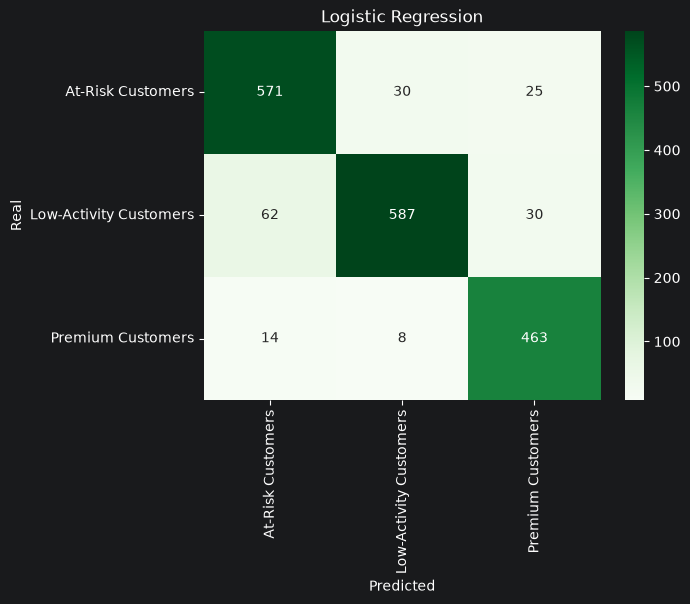

In [7]:

pipe_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(class_weight="balanced", max_iter=1000)),
])

pipe_lr.fit(X_train, y_train)

pred = pipe_lr.predict(X_test)
prec, rec, f1, _ = precision_recall_fscore_support(y_test, pred, average="weighted")
rows.append({"model": "Logistic Regression", "accuracy": accuracy_score(y_test, pred),
             "precision": prec, "recall": rec, "f1": f1})
cv_scores["Logistic Regression"] = cross_val_score(pipe_lr, X_train, y_train, cv=5, scoring="f1_weighted")

sns.heatmap(confusion_matrix(y_test, pred, labels=labels), annot=True, fmt="d",
            cmap="Greens", xticklabels=labels, yticklabels=labels)
plt.title("Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Real")
plt.show()


                     accuracy  precision  recall     f1
model                                                  
Random Forest           0.962      0.962   0.962  0.962
Decision Tree           0.934      0.934   0.934  0.934
Logistic Regression     0.906      0.907   0.906  0.905
SVM                     0.899      0.904   0.899  0.899


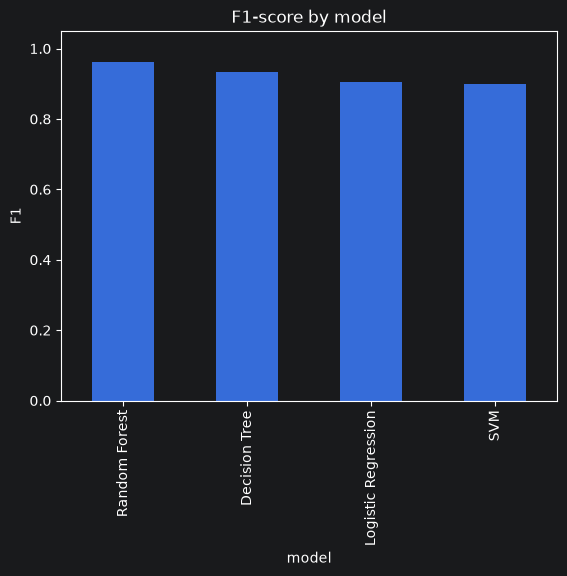

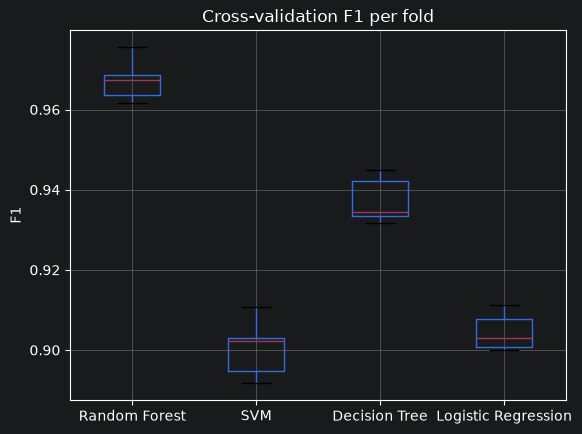

Best parameters: {'classifier__max_depth': 10, 'classifier__n_estimators': 200}
Best CV F1: 0.968
Test accuracy: 0.962


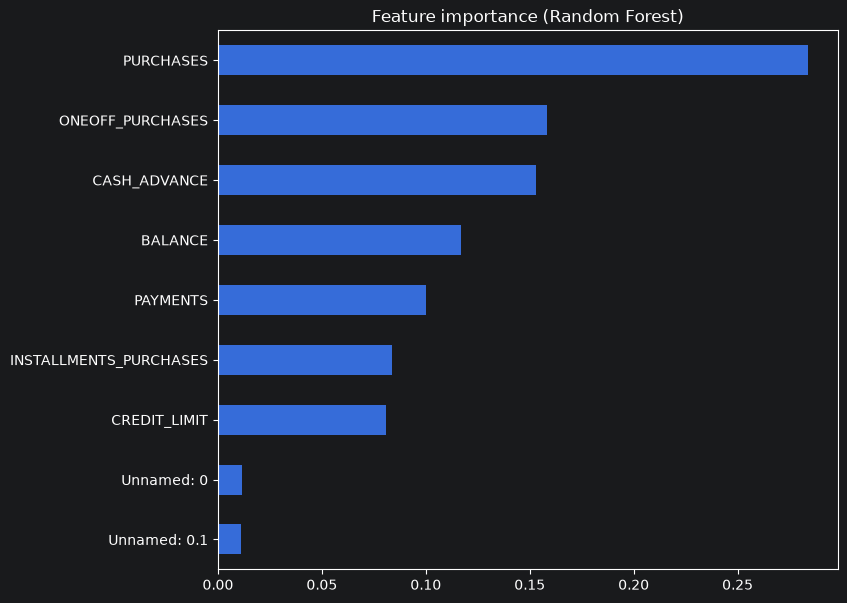

Saved.


In [9]:
comparison = pd.DataFrame(rows).set_index("model").sort_values("f1", ascending=False)
print(comparison.round(3))

comparison["f1"].plot(kind="bar")
plt.title("F1-score by model")
plt.ylabel("F1")
plt.ylim(0, 1.05)
plt.show()

pd.DataFrame(cv_scores).boxplot()
plt.title("Cross-validation F1 per fold")
plt.ylabel("F1")
plt.show()

param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
}
grid = GridSearchCV(pipe_rf, param_grid, cv=5, scoring="f1_weighted")
grid.fit(X_train, y_train)

best_model = grid.best_estimator_
print("Best parameters:", grid.best_params_)
print("Best CV F1:", round(grid.best_score_, 3))
print("Test accuracy:", round(best_model.score(X_test, y_test), 3))

importance = best_model.named_steps["classifier"].feature_importances_
pd.Series(importance, index=X.columns).sort_values().plot(kind="barh", figsize=(8, 7))
plt.title("Feature importance (Random Forest)")
plt.show()

joblib.dump(best_model, "../models/pipeline_segmentation.joblib")
print("Saved.")